In [1]:
import sys, os, json, time, random
import torch
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model
sys.path.insert(0, "..")
import solucion

SEMILLA = 2026
BASE = os.environ.get("RUTA_MODELO", solucion.CONFIG["modelo_base"])
torch.manual_seed(SEMILLA)
tokenizer = AutoTokenizer.from_pretrained(BASE)
solucion.tokenizer = tokenizer
print(torch.__version__, "hilos:", torch.get_num_threads())

2.14.1+cu130 hilos: 4


## 1. Preparar los ejemplos

El prompt es el mismo que usa `solucion.py`. Solo calculamos la loss sobre la consulta SQL, no sobre el prompt.

In [2]:
pares = [json.loads(l) for l in open("../datos/entrenamiento.jsonl")]
esquemas = {b: open(f"../datos/esquemas_sql/{b}.sql").read() for b in {p["base"] for p in pares}}

def ejemplo(esquema, pregunta, sql):
    prompt = solucion.armar_prompt(solucion.armar_mensajes(esquema, pregunta))
    ids_prompt = tokenizer(prompt)["input_ids"]
    ids_sql = tokenizer(sql + "<|im_end|>")["input_ids"]
    return {"input_ids": ids_prompt + ids_sql, "labels": [-100] * len(ids_prompt) + ids_sql}

random.seed(SEMILLA)
muestra = random.sample(pares, 300)
entrenamiento = [ejemplo(esquemas[p["base"]], p["pregunta"], p["sql"]) for p in muestra]
print("Ejemplos de entrenamiento:", len(entrenamiento))
print(pd.Series([p["nivel"] for p in muestra]).value_counts())

val = json.load(open("../datos/validacion_propia.json"))
esq_val = {b: open(f"../datos/esquemas_sql/{b}.sql").read() for b in {v["base"] for v in val}}
validacion = [ejemplo(esq_val[v["base"]], v["pregunta"], v["sql"]) for v in val[::2]]

Ejemplos de entrenamiento: 300
facil      121
media      109
dificil     70
Name: count, dtype: int64


## 2. Funcion de entrenamiento

Usamos un ciclo simple de PyTorch. Cada paso de optimizacion acumula 8 ejemplos. Al inicio y al final medimos la loss sobre 20 de las 40 preguntas de validacion propia, una si y una no, para ahorrar tiempo.

In [3]:
ACUMULAR = 8
LR = 2e-4

def loss_validacion(modelo):
    modelo.eval()
    total = 0
    with torch.no_grad():
        for e in validacion:
            total += modelo(input_ids=torch.tensor([e["input_ids"]]), labels=torch.tensor([e["labels"]])).loss.item()
    modelo.train()
    return total / len(validacion)

def entrenar(r, carpeta):
    # Si la configuracion ya se entreno se cargan sus resultados guardados
    if os.path.exists(f"{carpeta}/resultado.json"):
        return json.load(open(f"{carpeta}/resultado.json"))
    torch.manual_seed(SEMILLA)
    modelo = AutoModelForCausalLM.from_pretrained(BASE, dtype=torch.bfloat16)
    config = LoraConfig(r=r, lora_alpha=32, lora_dropout=0.05, task_type="CAUSAL_LM",
                        target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
    modelo = get_peft_model(modelo, config)
    entrenables = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    print("Parametros entrenables:", entrenables)
    optim = torch.optim.AdamW([p for p in modelo.parameters() if p.requires_grad], lr=LR)
    modelo.train()
    curva, curva_val = [], [(0, loss_validacion(modelo))]
    inicio = time.time()
    acumulada = 0
    for i, e in enumerate(entrenamiento, 1):
        salida = modelo(input_ids=torch.tensor([e["input_ids"]]), labels=torch.tensor([e["labels"]]))
        (salida.loss / ACUMULAR).backward()
        acumulada += salida.loss.item() / ACUMULAR
        if i % ACUMULAR == 0:
            optim.step()
            optim.zero_grad()
            paso = i // ACUMULAR
            curva.append((paso, acumulada))
            acumulada = 0
            if i + ACUMULAR > len(entrenamiento):
                curva_val.append((paso, loss_validacion(modelo)))
                print(f"paso {paso} loss {curva[-1][1]:.4f} loss validacion {curva_val[-1][1]:.4f} minutos {(time.time() - inicio) / 60:.1f}")
    minutos = (time.time() - inicio) / 60
    modelo = modelo.to(torch.bfloat16)
    modelo.save_pretrained(carpeta)
    resultado = {"r": r, "parametros_entrenables": entrenables, "minutos": round(minutos, 1),
            "loss_final": round(curva[-1][1], 4), "loss_validacion_final": round(curva_val[-1][1], 4),
            "curva": curva, "curva_val": curva_val}
    json.dump(resultado, open(f"{carpeta}/resultado.json", "w"))
    return resultado

## 3. Configuracion A con r igual a 8

In [4]:
res_a = entrenar(8, "../adapters/lora_r8")

## 4. Configuracion B con r igual a 16

In [5]:
res_b = entrenar(16, "../adapters/lora_r16")

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Parametros entrenables: 17432576


paso 37 loss 0.0234 loss validacion 0.2372 minutos 40.1


## 5. Curvas de loss y resumen

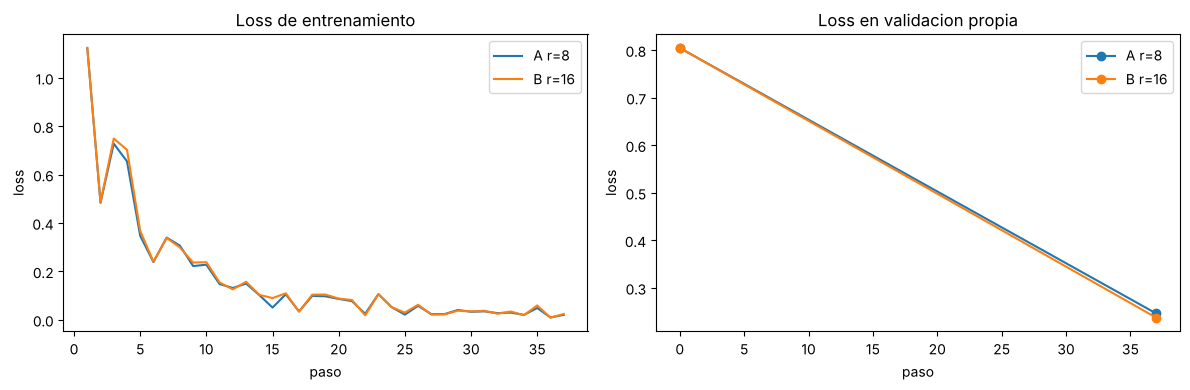

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for res, nombre in [(res_a, "A r=8"), (res_b, "B r=16")]:
    pasos, valores = zip(*res["curva"])
    ejes[0].plot(pasos, valores, label=nombre)
    pasos, valores = zip(*res["curva_val"])
    ejes[1].plot(pasos, valores, marker="o", label=nombre)
ejes[0].set_title("Loss de entrenamiento")
ejes[1].set_title("Loss en validacion propia")
for eje in ejes:
    eje.set_xlabel("paso")
    eje.set_ylabel("loss")
    eje.legend()
plt.tight_layout()
os.makedirs("../resultados", exist_ok=True)
plt.savefig("../resultados/curvas_loss.png", dpi=120)
plt.show()

In [7]:
resumen = pd.DataFrame([{k: v for k, v in res.items() if not k.startswith("curva")} for res in [res_a, res_b]], index=["A", "B"])
resumen.to_csv("../resultados/resumen_entrenamiento.csv")
json.dump({"A": res_a, "B": res_b}, open("../resultados/curvas_loss.json", "w"))
resumen

,r,parametros_entrenables,minutos,loss_final,loss_validacion_final
A,8,8716288,53.8,0.0199,0.2460
B,16,17432576,41.7,0.0234,0.2372


## Conclusion

La comparacion final entre A y B se hace en el notebook de evaluacion con exactitud por ejecucion, que es la metrica que importa. Aqui solo vemos la loss, los parametros entrenables y el tiempo de cada configuracion.